
MODELO               | ACCURACY PROMEDIO
---------------------------------------------
Logística            | 77.08%
KNN                  | 69.92%
Árbol                | 71.10%
Random Forest        | 75.25%


C:\Users\Rafael\AppData\Local\Temp\ipykernel_22684\117398680.py:43: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(resultados_clas, labels=nombres_clas, patch_artist=True)


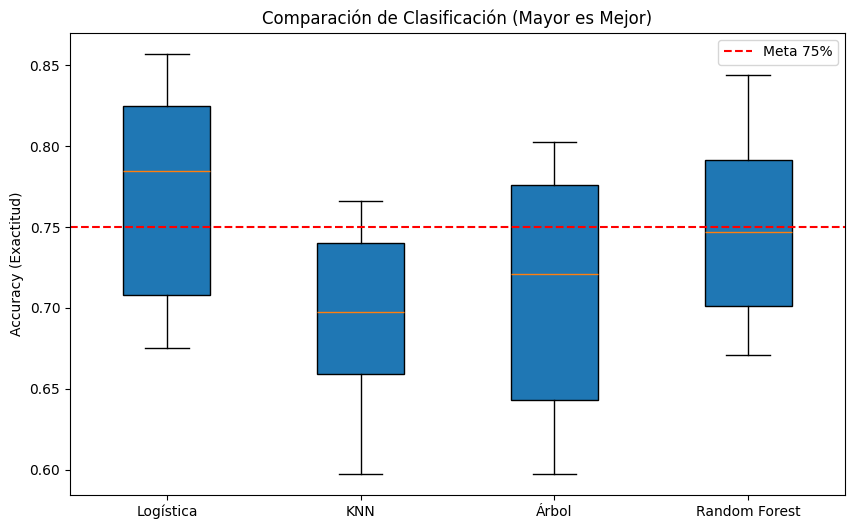

In [ ]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Cargar diabetes
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
names = ['preg', 'plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age', 'class']
dataframe = pd.read_csv(url, names=names)
array = dataframe.values
X_clas = array[:,0:8]
Y_clas = array[:,8]

# 1. Definir Modelos
modelos_clas = []
modelos_clas.append(('Logística', LogisticRegression(max_iter=1000)))
modelos_clas.append(('KNN', KNeighborsClassifier()))
modelos_clas.append(('Árbol', DecisionTreeClassifier()))
modelos_clas.append(('Random Forest', RandomForestClassifier(n_estimators=100)))

# 2. Torneo
resultados_clas = []
nombres_clas = []

print(f"\n{'MODELO':<20} | {'ACCURACY PROMEDIO':<15}")
print("-" * 45)

for nombre, modelo in modelos_clas:
    kfold = KFold(n_splits=10, shuffle=True, random_state=42)
    cv_results = cross_val_score(modelo, X_clas, Y_clas, cv=kfold, scoring='accuracy')
    
    resultados_clas.append(cv_results)
    nombres_clas.append(nombre)
    
    print(f"{nombre:<20} | {cv_results.mean():.2%}")

# 3. Gráfico
plt.figure(figsize=(10, 6))
plt.boxplot(resultados_clas, labels=nombres_clas, patch_artist=True)
plt.title('Comparación de Clasificación (Mayor es Mejor)')
plt.ylabel('Accuracy (Exactitud)')
plt.axhline(y=0.75, color='r', linestyle='--', label='Meta 75%') # Línea de referencia
plt.legend()
plt.show()